# 02 Baselines

Phase 2 walkthrough: the split, the shrinkage tuning, the six baselines and how they score, and the sanity comps.

This notebook **only reads**. It imports the code in `src/` and never writes `reports/phase2_baselines.md` (running `evaluate.py` would overwrite the report's Findings section). Numbers are on the **validation** split; the test split and the five hold-outs are never touched.

Running everything takes under a minute.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from baselines import ALL, B0Random, load
from evaluate import KNOWN_PAIRS, PAIR_PARTNERS, SANITY, comp_players, era_and_position, next_season, retrieval
import tune_shrinkage as ts

pd.set_option("display.width", 140)
df = load(ROOT)  # qualified seasons with their split
holdouts = {p["player_id"] for p in json.loads((ROOT / "config" / "holdout.json").read_text())["players"]}
train = df[df["split"] == "train"].reset_index(drop=True)
val = df[df["split"] == "val"].reset_index(drop=True)
trval = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
pool = df[~df["player_id"].isin(holdouts)]
print(f"{len(df):,} qualified seasons, {df['player_id'].nunique():,} players")

14,749 qualified seasons, 2,472 players


## 1. The split

Players (not seasons) are shuffled within each debut decade and cut 70/15/15 with seed 2026, so a player's seasons never appear in two sets. Hold-outs are forced into test.

In [2]:
splits = pd.read_parquet(ROOT / "data" / "processed" / "splits.parquet")
summary = pd.DataFrame({
    "players": splits["split"].value_counts(),
    "qualified seasons": df["split"].value_counts(),
}).reindex(["train", "val", "test"])
display(summary)
display(pd.crosstab(splits["debut_decade"], splits["split"])[["train", "val", "test"]])
assert not set(holdouts) & set(df.loc[df["split"] != "test", "player_id"]), "a hold-out leaked out of test"

,players,qualified seasons
split,,
train,2670,10257
val,572,2263
test,577,2229


split,train,val,test
debut_decade,,,
1980,615,132,133
1990,481,103,105
2000,482,103,104
2010,580,124,126
2020,512,110,109


## 2. Shrinkage priors

Shooting percentages on few attempts are noisy, so each is pulled toward the league average: `(made + k * league%) / (attempts + k)`. The best `k` is the one whose shrunk season-t value best predicts the player's raw percentage in season t+1 (training players only).

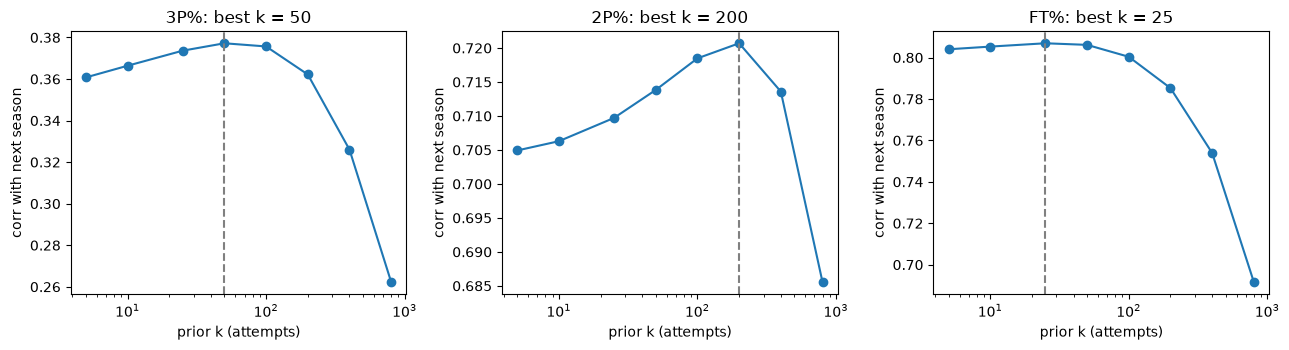

Chosen priors: {'3P%': 50, '2P%': 200, 'FT%': 25} (expected 3P% 50, 2P% 200, FT% 25)


In [3]:
cols = ["player_id", "season", "qualified"] + [c for m, a, _ in ts.STATS.values() for c in (m, a)]
seasons = pd.read_parquet(ts.SEASONS, columns=cols)
train_ids = set(splits.loc[splits["split"] == "train", "player_id"])
pairs = ts.season_pairs(seasons[seasons["player_id"].isin(train_ids)])
pairs = pairs[pairs["qualified"]]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
chosen = {}
for ax, (stat, (makes, attempts, min_next)) in zip(axes, ts.STATS.items()):
    league = ts.league_pct(seasons, makes, attempts)
    p = pairs[pairs[f"{attempts}_next"] >= min_next]
    corr = {k: ts.score(p, league, makes, attempts, k) for k in ts.CANDIDATES}
    best = max(corr, key=corr.get)
    chosen[stat] = best
    ax.plot(list(corr), list(corr.values()), marker="o")
    ax.axvline(best, ls="--", c="grey")
    ax.set(xscale="log", title=f"{stat}: best k = {best}", xlabel="prior k (attempts)", ylabel="corr with next season")
plt.tight_layout(); plt.show()
print("Chosen priors:", chosen, "(expected 3P% 50, 2P% 200, FT% 25)")

## 3. Baselines on validation

| Baseline | Idea |
|---|---|
| B0 random | What chance looks like |
| B1 Euclidean | Straight-line distance on the 15 style z-scores |
| B2 cosine | Profile shape, ignoring overall volume |
| B3 CARMELO-style | `100 - k * sum(w * abs(dz))` with CARMELO's weights |
| B3w | B3 on a 3/2/1 window of seasons t, t-1, t-2 |
| B4 PCA | Euclidean on the components covering 90% of variance |

In [4]:
rows, models = [], {}
for cls in ALL:
    model = cls().fit(train)
    models[model.name] = model
    r = {"model": model.name}
    ret = retrieval(model, val)
    r.update({"hit@10": ret["hit10"], "MRR": ret["mrr"]})
    r["non-adj hit@10"] = retrieval(model, val, non_adjacent=True)["hit10"]
    ns = next_season(model, val)
    r.update({"next RMSE": ns["rmse"], "vs persistence": ns["vs_persistence"]})
    r.update({"era": np.nan, "position": np.nan} if isinstance(model, B0Random) else era_and_position(model, trval))
    rows.append(r)
    print("done", model.name)
res = pd.DataFrame(rows).set_index("model")
persistence = ns["persistence"]
display(res.style.format({"vs persistence": "{:+.1%}"}, precision=3, na_rep="n/a"))
print(f"Persistence RMSE: {persistence:.3f}")

done B0 random


done B1 Euclidean


done B2 cosine


done B3 CARMELO-style


done B3w CARMELO 3-season


done B4 PCA


,hit@10,MRR,non-adj hit@10,next RMSE,vs persistence,era,position
model,,,,,,,
B0 random,0.042,0.022,0.034,0.652,+6.8%,n/a,n/a
B1 Euclidean,0.798,0.576,0.678,0.610,+0.0%,0.190,0.661
B2 cosine,0.778,0.561,0.668,0.608,-0.4%,0.190,0.661
B3 CARMELO-style,0.762,0.543,0.644,0.614,+0.7%,0.190,0.661
B3w CARMELO 3-season,0.964,0.893,0.826,0.625,+2.5%,0.186,0.674
B4 PCA,0.737,0.480,0.608,0.614,+0.6%,0.188,0.642


Persistence RMSE: 0.610


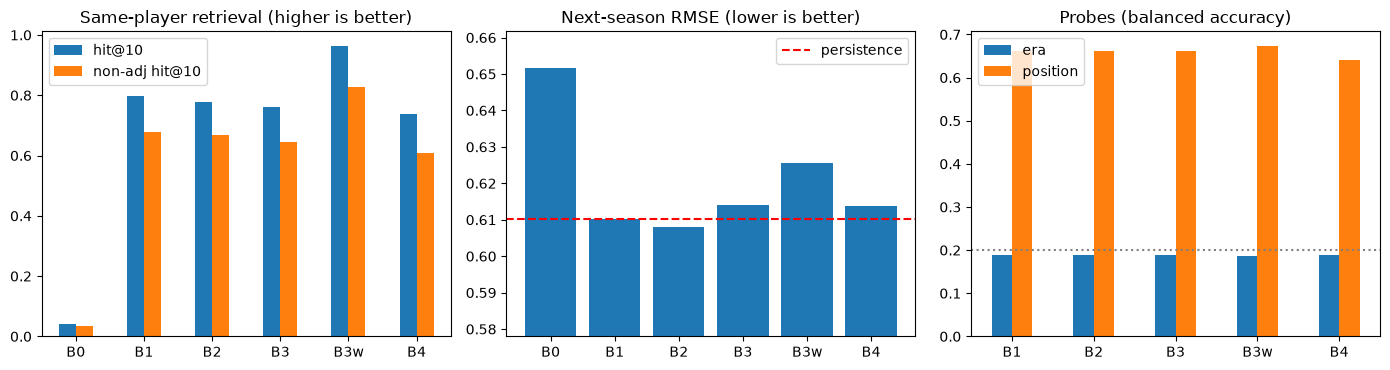

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
names = [n.split()[0] for n in res.index]
res[["hit@10", "non-adj hit@10"]].set_axis(names).plot.bar(ax=axes[0], rot=0, title="Same-player retrieval (higher is better)")
axes[1].bar(names, res["next RMSE"]); axes[1].axhline(persistence, c="red", ls="--", label="persistence")
axes[1].set(ylim=(res["next RMSE"].min() - 0.03, res["next RMSE"].max() + 0.01), title="Next-season RMSE (lower is better)"); axes[1].legend()
probes = res[["era", "position"]].dropna().set_axis([n.split()[0] for n in res.dropna().index])
probes.plot.bar(ax=axes[2], rot=0, title="Probes (balanced accuracy)"); axes[2].axhline(0.2, c="grey", ls=":", label="chance")
plt.tight_layout(); plt.show()

**Reading it**

- Every baseline beats random on retrieval. B3w's retrieval is inflated: its window shares raw seasons between neighbouring rows of the same player, so compare it on next-season error and comps only.
- Only B2 cosine beats persistence on next-season error, and only by about 0.4%. Persistence is a hard bar.
- Era leakage sits at chance (about 0.19 against 0.20): within-season z-scores already remove the decade signal a linear probe can see. Position is well above chance (about 0.65).

## 4. Sanity comps

Top 5 comp players for each sanity player (each comp counted once, best-matching season), from a pool that excludes the hold-outs. Verdicts come from `config/sanity_marks.json`: fair = 1, partial = 0.5, wrong = 0, summed over the top 5; pass if 2 or more, partial if above 0, fail if 0. Marks were made without looking at the stats (see `notes/sanity_judgements.md`).

In [6]:
marks_raw = json.loads((ROOT / "config" / "sanity_marks.json").read_text())
POINTS = {"fair": 1.0, "partial": 0.5, "wrong": 0.0}
marks = {p: {n: POINTS[k] for k, ns in v.items() for n in ns} for p, v in marks_raw["players"].items()}
aliases = marks_raw.get("aliases", {})

scores, tops = {}, {}
for mname, model in models.items():
    if isinstance(model, B0Random):
        continue
    for pid, pname in SANITY.items():
        top = comp_players(model, df[df["player_id"] == pid], pool, n=5)
        names = [aliases.get(n, n) for n in top["player"]]
        tops[(pname, mname)] = ", ".join(f"{n} {s}" for n, s in zip(top["player"], top["season"]))
        scores[(pname, mname)] = sum(marks[pname].get(n, np.nan) for n in names)

score_tab = pd.Series(scores).unstack()[[m for m in models if not m.startswith("B0")]]
score_tab = score_tab.reindex(list(SANITY.values()))
assert not score_tab.isna().any().any(), "a comp has no mark: the comps differ from the report"
verdict = score_tab.map(lambda s: "pass" if s >= 2 else ("partial" if s > 0 else "fail"))
summary = pd.DataFrame({v: (verdict == v).sum() for v in ["pass", "partial", "fail"]})
summary["mean score"] = score_tab.mean().round(2)
display(summary)

,pass,partial,fail,mean score
B1 Euclidean,4,9,2,1.27
B2 cosine,6,8,1,1.70
B3 CARMELO-style,5,9,1,1.30
B3w CARMELO 3-season,6,7,2,1.37
B4 PCA,3,10,2,1.20


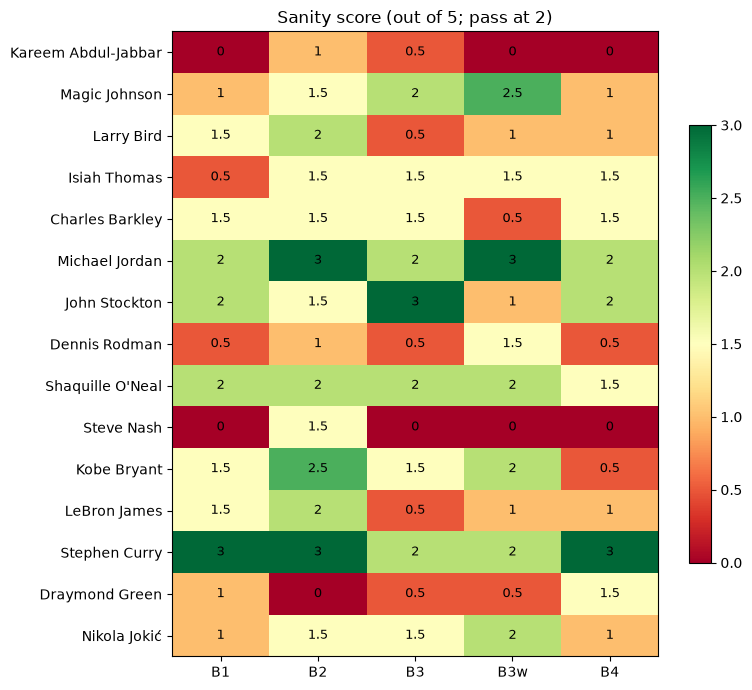

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(score_tab.to_numpy(), cmap="RdYlGn", vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(score_tab.shape[1]), [c.split()[0] for c in score_tab.columns])
ax.set_yticks(range(score_tab.shape[0]), score_tab.index)
for i in range(score_tab.shape[0]):
    for j in range(score_tab.shape[1]):
        ax.text(j, i, f"{score_tab.iat[i, j]:g}", ha="center", va="center", fontsize=9)
ax.set_title("Sanity score (out of 5; pass at 2)")
fig.colorbar(im, ax=ax, shrink=0.7); plt.tight_layout(); plt.show()

In [8]:
# Look at any player's top 5 under every model
player = "Michael Jordan"
pd.DataFrame({m.split()[0]: [tops[(player, m)]] for m in score_tab.columns}, index=[player]).T

,Michael Jordan
B1,"James Worthy 1992, Caris LeVert 2021, Kobe Bry..."
B2,"Kobe Bryant 2000, George Gervin 1981, Tracy Mc..."
B3,"Kobe Bryant 2004, Dwyane Wade 2013, Kawhi Leon..."
B3w,"Kobe Bryant 2004, Dwyane Wade 2013, George Ger..."
B4,"James Worthy 1992, Dwyane Wade 2012, Clyde Dre..."


In [9]:
# Known pairs: is each player in the other's top 5?
names = {**SANITY, **PAIR_PARTNERS}
rows = []
for mname, model in models.items():
    if isinstance(model, B0Random):
        continue
    for a, b in KNOWN_PAIRS:
        ta = set(comp_players(model, df[df["player_id"] == a], pool, n=5)["player_id"])
        tb = set(comp_players(model, df[df["player_id"] == b], pool, n=5)["player_id"])
        hits = (b in ta) + (a in tb)
        rows.append({"model": mname, "pair": f"{names[a]} / {names[b]}", "result": ["fail", "partial", "pass"][hits]})
pd.DataFrame(rows).pivot(index="pair", columns="model", values="result")

model,B1 Euclidean,B2 cosine,B3 CARMELO-style,B3w CARMELO 3-season,B4 PCA
pair,,,,,
Michael Jordan / Kobe Bryant,partial,pass,partial,partial,fail
Shaquille O'Neal / Dwight Howard,pass,pass,pass,partial,pass
Steve Nash / Chris Paul,fail,fail,fail,fail,fail


## 5. What Phase 2 tells Phase 3

- **The bar to beat:** B2 cosine. It has the best sanity record (mean about 1.70 of 5) and is the only baseline that beats persistence.
- **The main gap:** most comps are role players who share a star's stat shape but not his level or role. Kareem, Nash and Rodman fail or barely pass under almost every model, and Draymond has no fair comp anywhere.
- **Known pairs:** Nash and Paul fail everywhere, a concrete target for the encoder.
- **Era:** with linear leakage already at chance, Phase 4 needs a stronger test (a nonlinear probe) to show anything.

The Phase 3 encoder plugs into the same `fit` / `embed` / `similarity` interface, so every cell above can score it unchanged.